# Sparse Impulsive-Noise Removal
## Classical detection and repair versus pretrained neural enhancement

**Research question:** For sparse short-duration interference in speech, how does event-localised DSP compare with a general pretrained enhancer in event restoration, preservation of surrounding speech, and CPU cost?

This is the main project notebook. It contains a controlled example, the development-only threshold procedure, measured benchmark results, figures, listening examples, and limitations. Supporting modules hold the reusable implementation; they are not separate experiments.

The benchmark uses two synthetic pulses and three real ESC-50 transients, with 90 development mixtures and 180 held-out mixture variants. The recording and variants are not independent speakers.

**Setup:** clone/download the repository, install `requirements.txt`, and run `python scripts/prepare_data.py` once from the repository root. Open this notebook in Jupyter or VS Code and run all cells. The saved outputs can be read without rerunning. `RUN_FULL_EXPERIMENT` below controls whether to recompute the complete benchmark; the default loads the recorded measurements.



In [1]:
from pathlib import Path
import sys, json, csv, io, subprocess
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Markdown, Image, Audio

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/dsp.py').exists() and (p/'audio/clean_speech.wav').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the project checkout.')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/'scripts'))
from src.dsp import FS, features, detect, repair, regions, inject, detection_counts, prf
from src.neural import GTCRNEnhancer
from run_experiment import clips_from_source, event_bank, make_cases, calibrate
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})

def markdown_table(headers, rows):
    lines=['| '+' | '.join(headers)+' |', '| '+' | '.join(['---']*len(headers))+' |']
    lines += ['| '+' | '.join(str(v) for v in row)+' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def csv_rows(name):
    with (ROOT/'results'/name).open() as handle:
        return list(csv.DictReader(handle))

def show_figure(name):
    # Compact embedded preview; full-resolution originals remain in docs/assets.
    with PILImage.open(ROOT/'docs/assets/figures'/name) as img:
        img=img.convert('RGB');img.thumbnail((1100,1000))
        buffer=io.BytesIO();img.save(buffer,format='PNG',optimize=True)
    display(Image(data=buffer.getvalue()))

## 1. Reference signal and provenance

The recording is `OSR_us_000_0010_8k.wav` from the Open Speech Repository. The inherited waveform is byte-identical to a public mirror; the official index lists the original as 8 kHz, 16-bit PCM Harvard sentences. The source permits reuse and modification with attribution as Open Speech Repository.

Resampling to 16 kHz does not recover information above the original Nyquist frequency. A shared global peak scale of 0.15 provides headroom. Mixtures and enhanced outputs are not independently normalized.

Six non-overlapping 5-second clips use the first 30 seconds. Clips 1–2 are development inputs; clips 3–6 form the evaluation split. These clips share one source recording and recording conditions, so this is not a speaker-generalisation test. Unmodified reference audio is not certified noise-free.

In [2]:
speech_manifest=json.loads((ROOT/'data/speech_manifest.json').read_text())
clips=clips_from_source()
markdown_table(['Split','Clips','Reference duration'],[
    ['Development','clip1–clip2','10 s'],['Evaluation','clip3–clip6','20 s']])
print('Source:',speech_manifest['source_name'],speech_manifest['source_filename'])
print('SHA-256:',speech_manifest['sha256'])

| Split | Clips | Reference duration |
| --- | --- | --- |
| Development | clip1–clip2 | 10 s |
| Evaluation | clip3–clip6 | 20 s |

Source: Open Speech Repository OSR_us_000_0010_8k.wav
SHA-256: a4bf9becd046d7aedb6d05b6e12347a6294a44f74d263089c636fb0a2b1e6561


## 2. Controlled corruption

Synthetic events are Hann-windowed Gaussian bursts of 5 and 20 ms. Real events are short crops around the strongest transient in three ESC-50 recordings: a wooden door knock, a mouse click, and typing. The crop expands around a 2 ms RMS-envelope peak until it falls below 10% of that peak, with a maximum 75 ms extension per side, 2 ms guards, and short edge fades.

Each clip combines five event templates, three acoustic locations, and three strength levels (−6, 0, +6 dB), producing 45 mixtures. Event strength is RMS relative to a local reference interval extending 50 ms on either side; in low-energy regions it is floored at 10% of whole-clip speech RMS.

Locations are selected before detection: a low-energy gap, a harmonic stable-voiced candidate, and a rapid spectral-change candidate. They are acoustic proxies, not verified phoneme labels. The exact insertion mask is retained only for evaluation. Both detectors and GTCRN receive identical mixtures.

In [3]:
bank=event_bank()
cases=make_cases(clips,bank)
markdown_table(['Event','Type','Duration (ms)','Original file'],[
    [e['name'],e['kind'],f"{e['duration_ms']:.3f}",e.get('source','Generated')] for e in bank])
print('Development mixtures:',sum(c['split']=='development' for c in cases))
print('Evaluation mixtures:',sum(c['split']=='test' for c in cases))
assert len(cases)==270
assert all(np.array_equal(c['noisy'][~c['truth']],c['clean'][~c['truth']]) for c in cases)

| Event | Type | Duration (ms) | Original file |
| --- | --- | --- | --- |
| synthetic_5ms | synthetic | 5.000 | Generated |
| synthetic_20ms | synthetic | 20.000 | Generated |
| door_wood_knock | real | 31.375 | 1-101336-A-30.wav |
| mouse_click | real | 16.125 | 1-118206-A-31.wav |
| keyboard_typing | real | 18.312 | 1-137-A-32.wav |

Development mixtures: 90
Evaluation mixtures: 180


### Interactive example

Change the event, acoustic location, or strength in the next cell. The default uses a real mouse click overlapping a speech-transient candidate in clip 3. These controls affect only this example, not the benchmark or threshold selection.

The exact clean, event, mixture, and mask for any benchmark case can also be exported with `python scripts/export_case.py <case_id>`.

Case: clip3_mouse_click_speech_transient_+6dB
True interval: 2.644000–2.660125 s


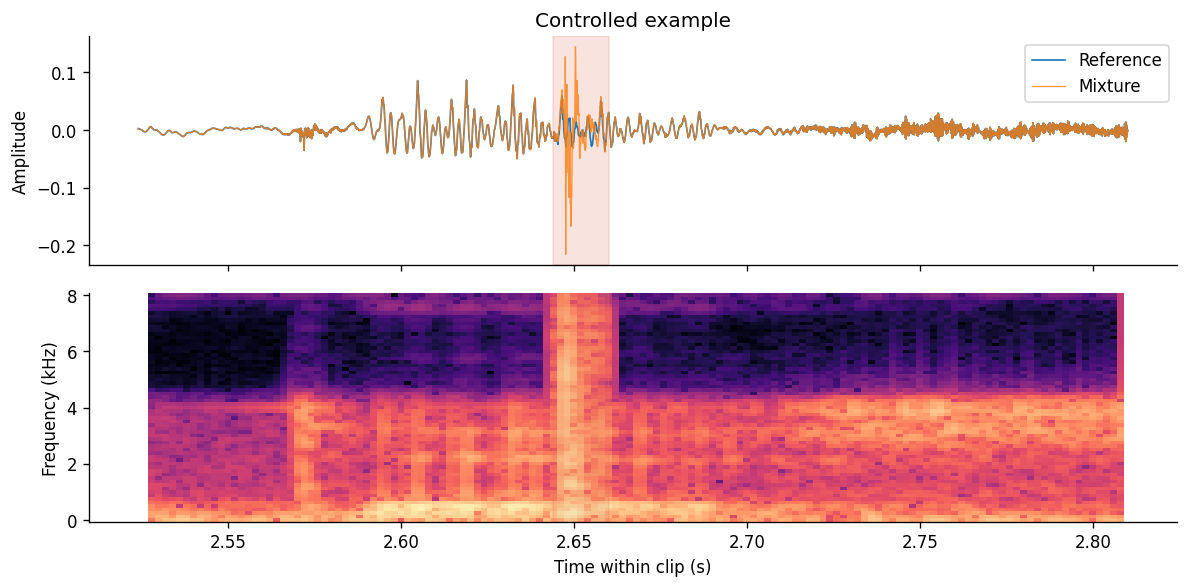

In [4]:
EVENT_NAME = 'mouse_click'
LOCATION = 'speech_transient'
LEVEL_DB = 6
example=next(c for c in cases if c['clip']=='clip3' and c['event']==EVENT_NAME
             and c['condition']==LOCATION and c['level_db']==LEVEL_DB)
print('Case:',example['id'])
print(f"True interval: {example['start_sample']/FS:.6f}–{example['end_sample']/FS:.6f} s")
a=max(0,example['start_sample']-round(.12*FS));b=min(len(example['clean']),example['end_sample']+round(.15*FS))
t=np.arange(a,b)/FS
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True)
axes[0].plot(t,example['clean'][a:b],label='Reference',lw=1)
axes[0].plot(t,example['noisy'][a:b],label='Mixture',lw=.8,alpha=.8)
axes[0].set(ylabel='Amplitude',title='Controlled example');axes[0].legend()
from scipy import signal
freq,time,z=signal.stft(example['noisy'][a:b],FS,nperseg=128,noverlap=96,boundary=None)
axes[1].pcolormesh(time+a/FS,freq/1000,20*np.log10(abs(z)+1e-8),shading='auto',cmap='magma')
axes[1].set(ylabel='Frequency (kHz)',xlabel='Time within clip (s)')
for ax in axes:ax.axvspan(example['start_sample']/FS,example['end_sample']/FS,color='#e27662',alpha=.2)
fig.tight_layout();plt.show()

## 3. Detection and development-only threshold selection

The energy baseline compares frame energy with a local median and a defined floor. The STFT detector combines positive energy rise, robustly normalized positive spectral flux, and spectral bandwidth. Analysis uses 8 ms frames and a 2 ms hop, with a Hann window and a 256-point FFT for spectral features. Zero-padding samples the spectrum more densely without improving physical frequency resolution.

The STFT score is `max(energy_rise, 0)/6 + max(flux_z, 0)/3 + bandwidth/1500`. Thresholded neighboring frames are mapped to sample intervals; candidates longer than 150 ms are excluded. Energy detection computes no FFT during its runtime measurement.

The grid search uses only development mixtures and their no-insertion controls. Its declared objective is event F1 after adding `45 × control_false_events` to the false-positive count, giving each control clip comparable weight to its 45 corrupted variants. This weighting is a design choice, not a universal error cost. Ties choose the larger threshold.

The procedure is offline: local median filtering and whole-clip normalization use future context. It is not claimed to be streaming.

In [5]:
thresholds,development_search=calibrate(cases,clips)
markdown_table(['Detector','Frozen threshold'],[[k,v] for k,v in thresholds.items()])
assert thresholds==json.loads((ROOT/'results/summary.json').read_text())['thresholds']
example_predictions={m:detect(example['noisy'],m,thresholds[m]) for m in thresholds}
rows=[]
for method,mask in example_predictions.items():
    counts=detection_counts(mask,example['truth']);metrics=prf(counts['tp'],counts['fp'],counts['fn'])
    rows.append([method.upper(),counts['tp'],counts['fp'],counts['fn'],f"{metrics['f1']:.3f}",
                 f"{np.mean(mask[example['truth']])*100:.1f}%"])
markdown_table(['Detector','TP','FP','FN','Event F1','True-mask sample coverage'],rows)

| Detector | Frozen threshold |
| --- | --- |
| energy | 9 |
| stft | 5 |

| Detector | TP | FP | FN | Event F1 | True-mask sample coverage |
| --- | --- | --- | --- | --- | --- |
| ENERGY | 1 | 2 | 0 | 0.500 | 87.2% |
| STFT | 1 | 0 | 0 | 1.000 | 37.6% |

## 4. Local repair and the pretrained baseline

Attenuation applies gain 0.2 within predicted regions with short ramps. Linear interpolation replaces the predicted interval with a line between its neighboring samples. Both preserve every sample outside the predicted mask exactly; false detections can still alter legitimate speech.

GTCRN uses the official DNS3 pretrained weights and pinned source commit, with no training or fine-tuning. The adapter uses a 512-sample STFT, 256-sample hop, and square-root Hann analysis/synthesis window. Modern complex tensors are converted to and from the model's real/imaginary input convention. Output length is preserved, with no case-specific gain or delay fitting against the clean reference.

True-mask interpolation is included only as a diagnostic of reconstruction quality when localisation is known. It is not a deployable detector and is excluded from runtime comparisons.

In [6]:
neural=GTCRNEnhancer(ROOT/'third_party/gtcrn')
example_outputs={'Reference':example['clean'],'Mixture':example['noisy'],
    'Energy + interpolation':repair(example['noisy'],example_predictions['energy'],'interpolate'),
    'STFT + attenuation':repair(example['noisy'],example_predictions['stft'],'attenuate'),
    'STFT + interpolation':repair(example['noisy'],example_predictions['stft'],'interpolate'),
    'GTCRN':neural(example['noisy'])}
for method in ['energy','stft']:
    y=example_outputs['Energy + interpolation' if method=='energy' else 'STFT + interpolation']
    assert np.array_equal(y[~example_predictions[method]],example['noisy'][~example_predictions[method]])
markdown_table(['Model quantity','Measured value'],[[k,v] for k,v in neural.metadata.items()])
# Use identical playback scale; do not normalize each signal separately.
lo=max(0,example['start_sample']-FS//2);hi=min(len(example['clean']),example['end_sample']+FS//2)
for name in ['Reference','Mixture','STFT + interpolation','GTCRN']:
    display(Markdown(f'**{name} — same-scale local excerpt**'))
    display(Audio(example_outputs[name][lo:hi],rate=FS,normalize=False))

| Model quantity | Measured value |
| --- | --- |
| checkpoint_sha256 | a630d992cf792daf4ce2bb5bcf9c4d389f740a8f09c6e0971184697fe6371b79 |
| parameters | 48245 |
| trainable_parameters | 23669 |
| parameter_bytes | 192980 |
| checkpoint_bytes | 579819 |
| torch_version | 2.14.1+cpu |
| threads | 1 |

**Reference — same-scale local excerpt**

Same-scale PCM-16 listening excerpt.

**Mixture — same-scale local excerpt**

Same-scale PCM-16 listening excerpt.

**STFT + interpolation — same-scale local excerpt**

Same-scale PCM-16 listening excerpt.

**GTCRN — same-scale local excerpt**

Same-scale PCM-16 listening excerpt.

## 5. Reproduce the complete benchmark

The next cell loads the committed measurements by default. Set `RUN_FULL_EXPERIMENT = True` to rerun the 180 evaluation mixtures, no-insertion controls, figures, and documentation using the frozen development procedure. This may take several minutes on a laptop.

The experiment times detector plus repair, or STFT plus neural inference plus inverse STFT, on the same CPU. Loading and one neural warm-up call are excluded. It processes original floating-point arrays; listening WAV exports are not used to compute metrics.

In [7]:
RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    subprocess.run([sys.executable,str(ROOT/'scripts/run_experiment.py')],cwd=ROOT,check=True)
    subprocess.run([sys.executable,str(ROOT/'scripts/build_deliverables.py')],cwd=ROOT,check=True)
else:
    print('Loading recorded benchmark outputs; the full experiment is not rerun in this cell.')
summary=json.loads((ROOT/'results/summary.json').read_text())
assert summary['test_mixtures']==180 and summary['development_mixtures']==90
assert neural.metadata['checkpoint_sha256']==summary['model']['checkpoint_sha256']
print('Recorded CPU:',summary['environment']['cpu'])
print('Evaluation mixtures:',summary['test_mixtures'],'; no-insertion controls:',summary['clean_test_seconds'],'s')

Loading recorded benchmark outputs; the full experiment is not rerun in this cell.
Recorded CPU: INTEL(R) XEON(R) PLATINUM 8573C
Evaluation mixtures: 180 ; no-insertion controls: 20 s


## 6. Detection metrics by strength and acoustic condition

Predictions and true intervals are matched one-to-one using positive overlap. A partial overlap counts as a hit, so event F1 is supplemented with sample coverage. Onset error applies only to matched events and does not represent missed events.

Figure 1 separates strength and acoustic location. The per-case CSVs also retain event type and duration; variants remain dependent because they share reference clips and templates.

| Detector | Precision | Recall | F1 | TP / FP / FN | Matched onset error (ms) | Sample recall |
| --- | --- | --- | --- | --- | --- | --- |
| ENERGY | 0.047 | 0.289 | 0.080 | 52 / 1062 / 128 | 3.77 | 0.234 |
| STFT | 0.521 | 0.278 | 0.362 | 50 / 46 / 130 | 2.76 | 0.087 |

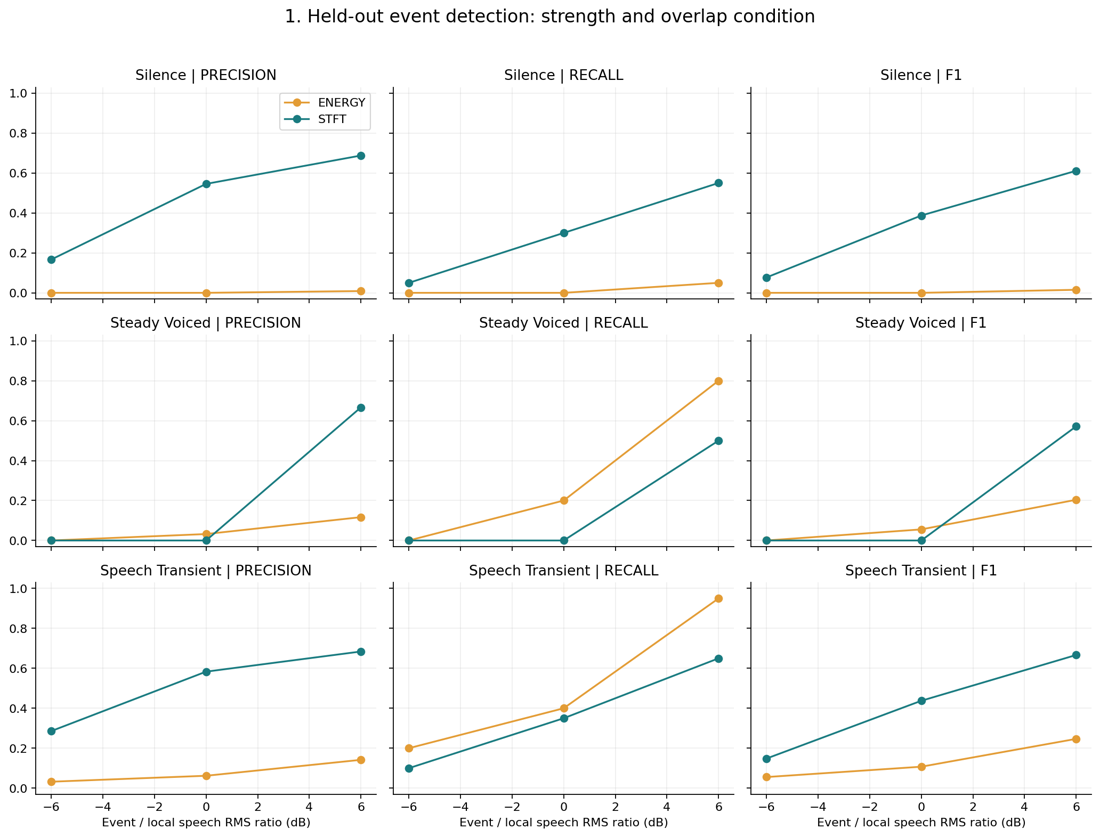

| Location | Detector | Precision | Recall | F1 |
| --- | --- | --- | --- | --- |
| silence | ENERGY | 0.003 | 0.017 | 0.005 |
| silence | STFT | 0.545 | 0.300 | 0.387 |
| speech_transient | ENERGY | 0.080 | 0.517 | 0.139 |
| speech_transient | STFT | 0.579 | 0.367 | 0.449 |
| steady_voiced | ENERGY | 0.052 | 0.333 | 0.091 |
| steady_voiced | STFT | 0.400 | 0.167 | 0.235 |

In [8]:
markdown_table(['Detector','Precision','Recall','F1','TP / FP / FN','Matched onset error (ms)','Sample recall'],[
    [method.upper(),f"{r['precision']:.3f}",f"{r['recall']:.3f}",f"{r['f1']:.3f}",
     f"{r['tp']} / {r['fp']} / {r['fn']}",f"{r['onset_error_ms_mean']:.2f}",f"{r['sample_metrics']['recall']:.3f}"]
    for method,r in summary['detection'].items()])
show_figure('01_detection.png')
groups=csv_rows('detection_groups.csv')
markdown_table(['Location','Detector','Precision','Recall','F1'],[
    [r['value'],r['detector'].upper(),*[f"{float(r[k]):.3f}" for k in ['precision','recall','f1']]]
    for r in groups if r['dimension']=='condition'])

## 7. Event restoration versus collateral alteration

Event RMSE uses only the true inserted interval. Collateral RMSE uses every sample outside that interval, including any repair of false detections and any global neural alteration. Event-error reduction is `10 log10(mixture event MSE / output event MSE)`; positive values mean improvement.

Whole-clip SI-SDR and STOI are secondary checks. A high global score can coexist with a noticeable short click because most samples are unchanged. Reported table values are arithmetic means of per-case metrics; median RTF is reported separately. A mean of dB improvements is not a dB ratio of mean errors.

| Method | Event RMSE | Collateral RMSE | Event improvement (dB) | SI-SDR (dB) | STOI |
| --- | --- | --- | --- | --- | --- |
| Unprocessed | 0.016776 | 0.000000 | 0.00 | 32.95 | 0.971 |
| Energy + interpolation | 0.013971 | 0.004933 | 1.25 | 12.13 | 0.877 |
| STFT + attenuation | 0.014943 | 0.000026 | 0.97 | 33.77 | 0.972 |
| STFT + interpolation | 0.014994 | 0.000062 | 1.15 | 33.64 | 0.974 |
| GTCRN | 0.006374 | 0.002243 | 5.87 | 17.89 | 0.899 |

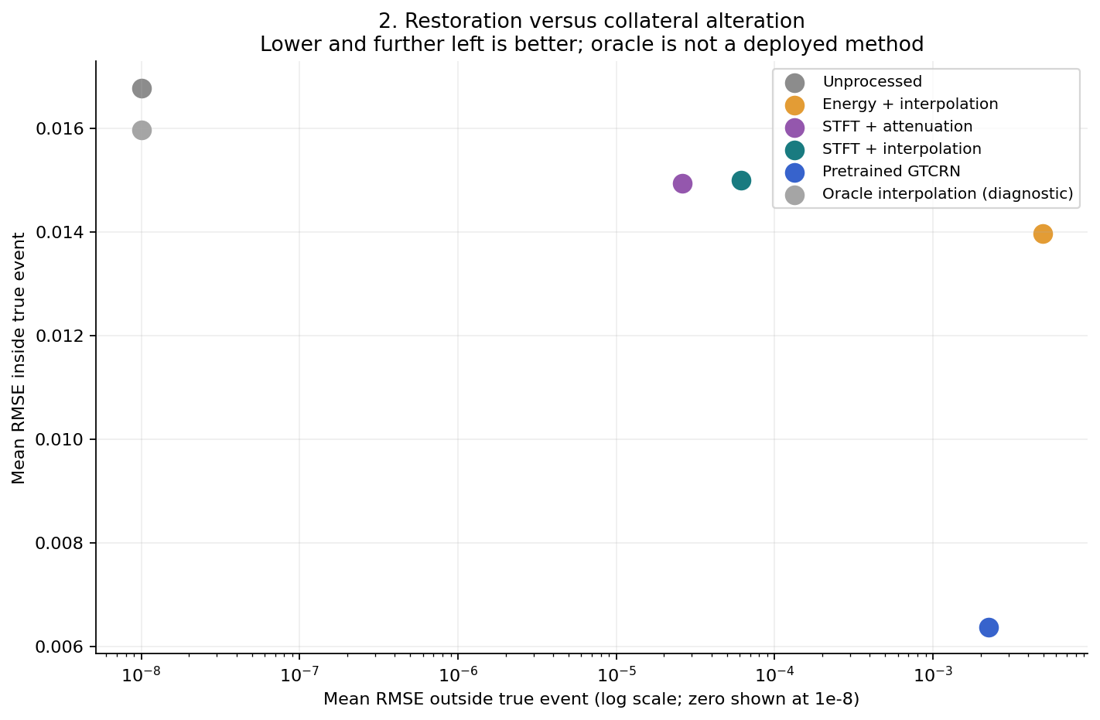

In [9]:
method_names={'noisy':'Unprocessed','energy_interpolate':'Energy + interpolation',
    'stft_attenuate':'STFT + attenuation','stft_interpolate':'STFT + interpolation','gtcrn':'GTCRN'}
markdown_table(['Method','Event RMSE','Collateral RMSE','Event improvement (dB)','SI-SDR (dB)','STOI'],[
    [label,f"{r['event_rmse_mean']:.6f}",f"{r['clean_rmse_mean']:.6f}",
     f"{r['event_error_reduction_db_mean']:.2f}",f"{r['si_sdr_db_mean']:.2f}",f"{r['stoi_mean']:.3f}"]
    for method,label in method_names.items() for r in [summary['restoration'][method]]])
show_figure('02_tradeoff.png')

## 8. The same physical event at different speech locations

This diagnostic moves precisely the same 20 ms event waveform at the same absolute amplitude among three locations. It is separate from the main grid, where the local RMS ratio is fixed and absolute event amplitude can vary.

The waveform panel and supplementary spectrogram compare reference, mixture, local outputs, and GTCRN. Acoustic labels do not establish consonant identities.

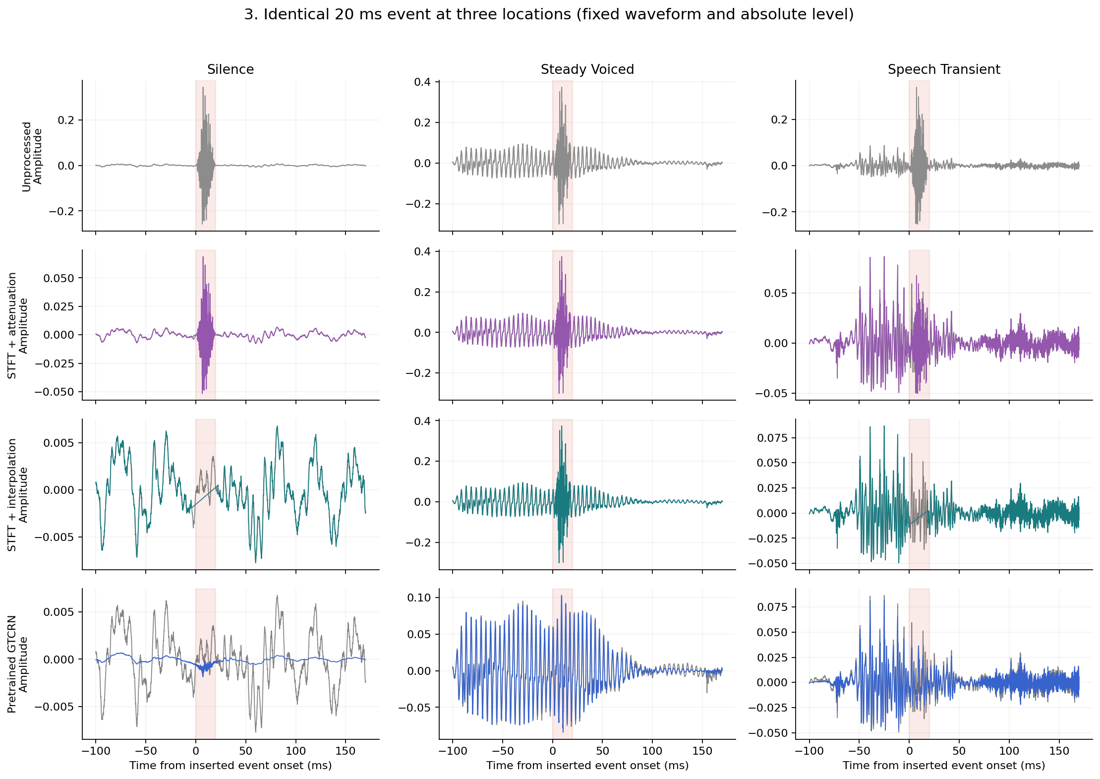

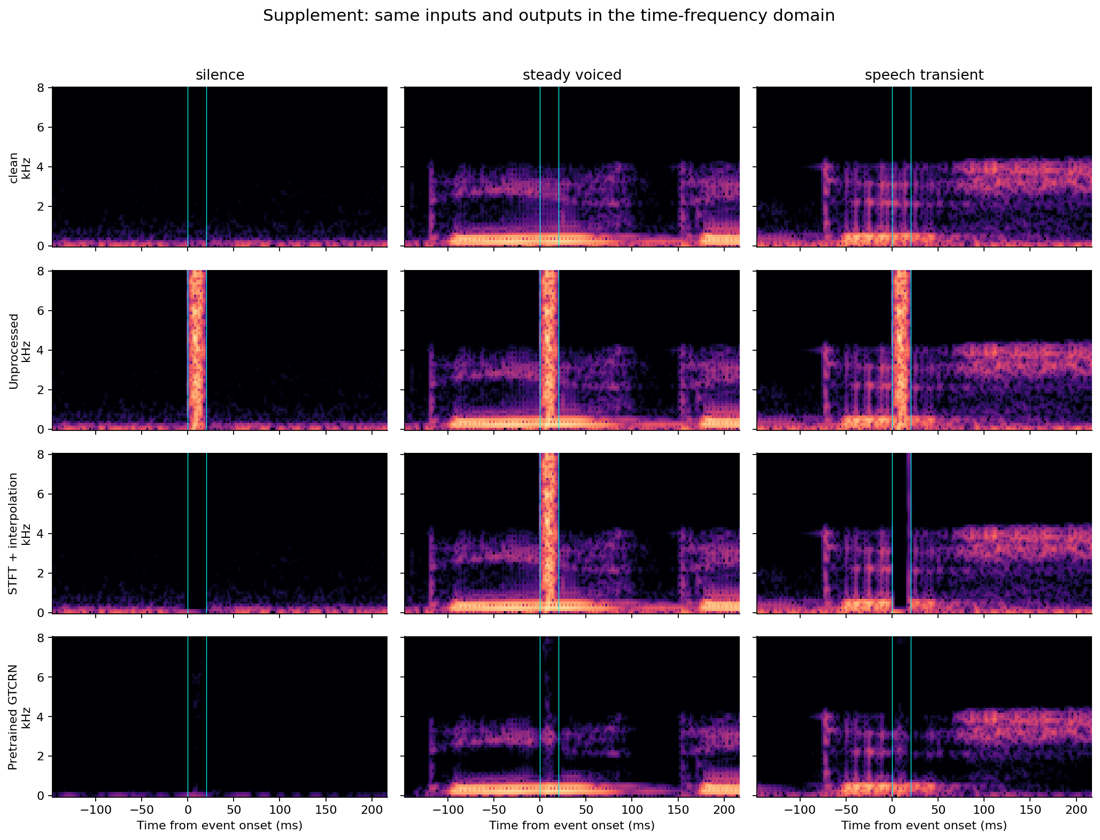

In [10]:
show_figure('03_overlap_waveforms.png')
show_figure('03_overlap_spectrograms.png')

## 9. No-insertion false alarms and preservation

Run the four evaluation reference clips with no inserted noise. For this controlled task, every detected event is a false positive and every waveform change is unwanted modification relative to the reference.

The false-alarm example shows waveform, spectrogram, energy, spectral flux, and detector score. A sharp relative spectral change can trigger the STFT detector even at low absolute energy. It is not assigned a /t/ or /k/ label without phoneme annotation.

Numerically changing samples does not prove that each change is audible or harmful. Listening examples support informal inspection only; no formal preference study was conducted.

| Pipeline | False events / 20 s | Mean reference RMSE | Changed samples |
| --- | --- | --- | --- |
| Energy + interpolation | 24 | 0.00492323 | 3.5575% |
| GTCRN | N/A | 0.00221101 | 100.0000% |
| STFT + interpolation | 1 | 0.00000564 | 0.0403% |

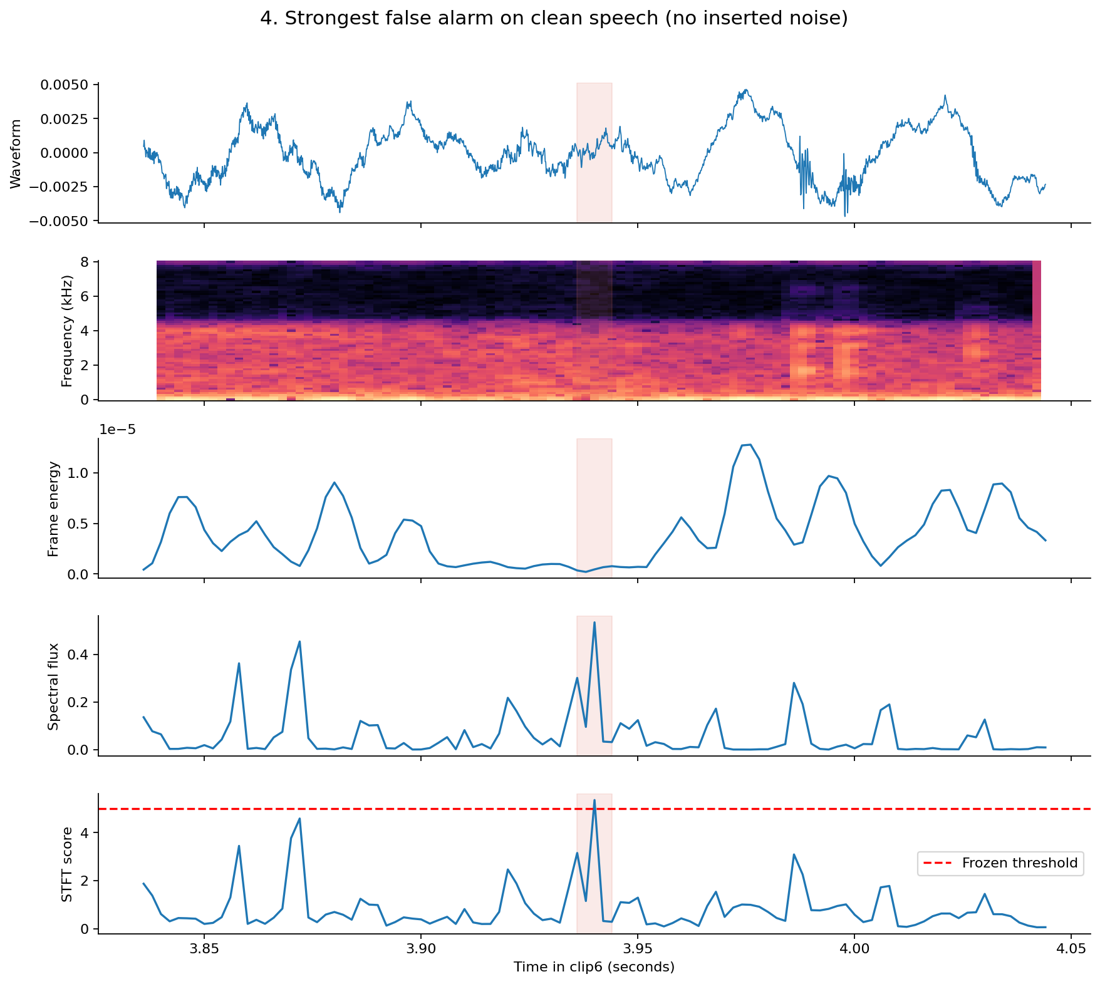

In [11]:
markdown_table(['Pipeline','False events / 20 s','Mean reference RMSE','Changed samples'],[
    [method_names[method],r['false_events'] if r['false_events'] is not None else 'N/A',
     f"{r['clean_rmse_mean']:.8f}",f"{100*r['changed_fraction_mean']:.4f}%"]
    for method,r in summary['clean_preservation'].items()])
show_figure('04_clean_false_positive.png')

## 10. Quality and computation

RTF is wall-clock processing time divided by audio duration, measured on the same machine for all systems. RTF below one indicates faster-than-duration offline throughput under these conditions, not streaming latency.

GTCRN storage counts parameter tensors and checkpoint bytes. These are not measurements of process peak memory. DSP has no learned weights but uses waveform, frame, median-filter, and FFT work buffers.

| Pipeline | Median CPU RTF |
| --- | --- |
| Energy + interpolation | 0.00030 |
| STFT + attenuation | 0.00183 |
| STFT + interpolation | 0.00183 |
| GTCRN | 0.01649 |

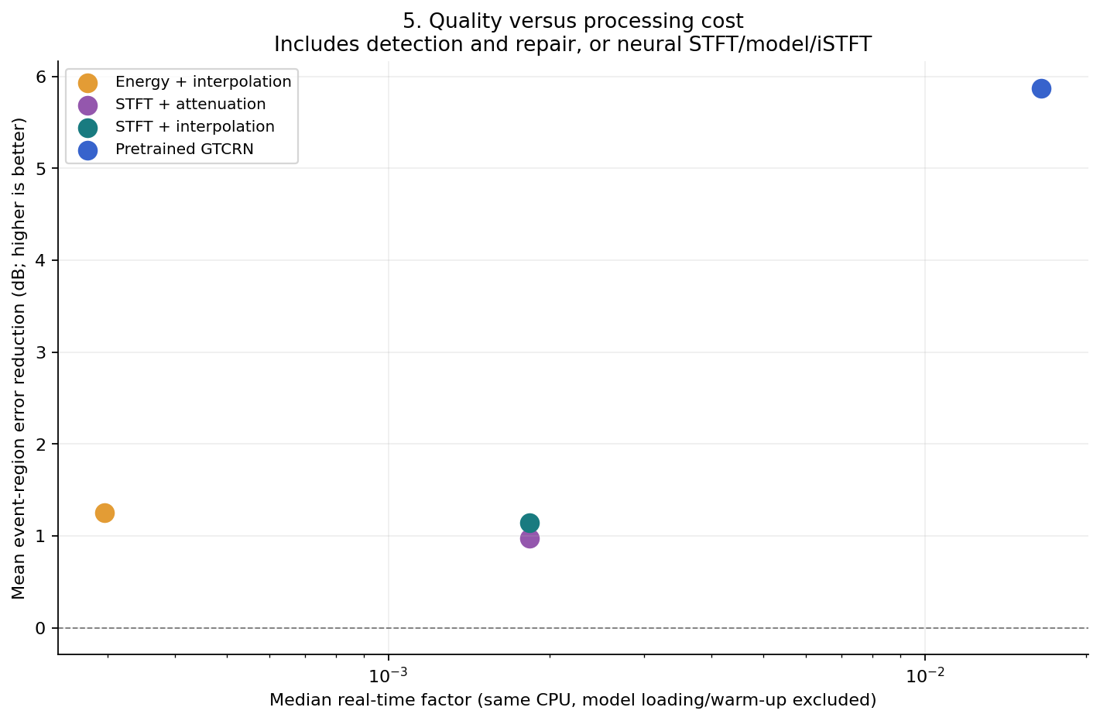

In [12]:
markdown_table(['Pipeline','Median CPU RTF'],[
    [label,f"{summary['restoration'][method]['rtf_median']:.5f}"]
    for method,label in method_names.items() if method!='noisy'])
show_figure('05_quality_runtime.png')

## 11. Interpretation and limitations

The STFT detector improves precision and event F1 relative to energy detection, but not recall. It misses 130 of 180 events and has sample recall of approximately 0.087. Its conservative behaviour limits useful repair.

GTCRN produces stronger event-region restoration, while the STFT local methods cause far less collateral waveform change. GTCRN's whole-clip STOI is lower than the sparse-corruption mixture despite lower event RMSE. Energy-driven interpolation damages speech through numerous false detections. Locality is therefore beneficial only when localisation is sufficiently reliable.

The speech-transient condition is not uniquely the hardest category in this small experiment. The acoustic proxies do not prove a plosive-overlap hypothesis. The 8 kHz source is upsampled for a general 16 kHz model, and domain mismatch may contribute to neural behaviour.

There is one reference recording and one real template per class. Mixture variants share speakers, recording conditions, and event waveforms. No independent-speaker significance claim, certified-clean-corpus claim, streaming claim, or universal ranking of DSP versus deep learning is justified.

The supported conclusion is to evaluate **event reconstruction, preservation of surrounding speech, and computation separately** when interference is sparse. Further work should expand independent speakers and transients, improve detector recall, and test one focused extension such as LPC reconstruction or detector-gated neural replacement.

## References and project navigation

- [Technical report](../report/final_report.md) and [PDF report](../report/final_report.pdf)
- [Revised proposal](../report/revised_proposal.pdf)
- [Case-level results and exact manifest](../results/)
- [Speech provenance](../data/speech_manifest.json)
- [Official GTCRN](https://github.com/Xiaobin-Rong/gtcrn)
- [ESC-50](https://github.com/karolpiczak/ESC-50)
- [Sparse adaptive filtering study](https://doi.org/10.1016/j.sigpro.2025.110390)

Full academic references and third-party attributions appear in the report and README.